# Начальный анализ YouTube Spam Collection и RDD2022

Первая самостоятельная работа от 21.10.2026. Анализ исходных данных, до ручного и синтетического обогащения.

Для RDD2022 исследуется **американская часть train**, а не весь набор из шести стран. Проверяются все 4 805 снимков этой части. Рабочие манифесты 1 500 текстов и 3 000 изображений предварительные; разбиение для обучения ещё не создаётся.

Источники: [UCI YouTube Spam](https://archive.ics.uci.edu/dataset/380/youtube+spam+collection), [RDD2022 Figshare](https://figshare.com/articles/dataset/RDD2022_-_The_multi-national_Road_Damage_Dataset_released_through_CRDDC_2022/21431547). Оба исходных набора — CC BY 4.0. Снимки в иллюстрациях: RDD2022, Arya и соавторы; добавлены рамки и подписи.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts' / 'eda.py').exists())
sys.path.insert(0, str(ROOT / 'scripts'))
from eda import run_all
print('Python', sys.version.split()[0])
print('Seed: 42')

Python 3.12.14
Seed: 42


## Загрузка данных

Архивы хранятся локально и не публикуются в Git. При первом запуске загрузчик получает официальный архив YouTube и только вложенный американский ZIP из официального Figshare. Это около 424 MiB, а не полный архив RDD2022 на 12 GiB. Проверяются CRC и SHA-256. Готовые данные можно повторно использовать.

In [2]:
import subprocess
required = ['youtube_spam.zip', 'RDD2022_United_States.zip']
if not all((ROOT / 'data' / 'raw' / name).exists() for name in required):
    subprocess.run([sys.executable, str(ROOT / 'scripts' / 'download_data.py')], check=True)
else:
    print('Оба исходных архива доступны локально')

Оба исходных архива доступны локально


## Проверки и расчёты

Тексты: пропуски, пустые строки, классы, точные повторы после strip, конфликтующие метки, длина, URL и HTML.

Изображения: читаемость всех train-файлов, соответствие XML и размеров, допустимость координат и классов, распределение объектов, точные повторы JPEG и пикселей, совпадения с официальным test. dHash с расстоянием ≤ 3 формирует кандидатов на близкие повторы; это эвристика, а не доказательство тождества.

Рамки проверяются по условию 0 ≤ xmin < xmax ≤ width и 0 ≤ ymin < ymax ≤ height. Площадь считается как (xmax − xmin)(ymax − ymin); это геометрическая оценка, не число пикселей маски.

In [3]:
summary = run_all()

RDD2022 checked 1000/4805 train images


RDD2022 checked 2000/4805 train images


RDD2022 checked 3000/4805 train images


RDD2022 checked 4000/4805 train images


{
  "generated_at_utc": "2026-10-21T12:00:57.602754+00:00",
  "youtube": {
    "raw_rows": 1956,
    "class_counts_raw": {
      "spam": 1005,
      "ham": 951
    },
    "missing_content": 0,
    "empty_content_after_strip": 0,
    "unknown_labels": 0,
    "duplicate_text_rows_after_strip": 197,
    "conflicting_unique_texts": 0,
    "unique_clean_rows": 1759,
    "class_counts_clean": {
      "ham": 919,
      "spam": 840
    },
    "rows_with_url": 202,
    "rows_with_html": 106,
    "provisional_working_rows": 1500,
    "seed": 42,
    "median_characters_clean": {
      "ham": 35.0,
      "spam": 78.0
    },
    "source_files": 5
  },
  "rdd2022_us": {
    "scope": "RDD2022 United States train; not the full multinational dataset",
    "train_images": 4805,
    "train_xml": 4805,
    "official_test_images_unlabeled": 1200,
    "readable_paired_train_images": 4805,
    "image_or_pair_errors": 0,
    "objects": 11014,
    "class_counts_objects": {
      "D00": 6750,
      "D10": 3295,

## YouTube Spam Collection

,class,raw,unique_clean
0,ham,951,919
1,spam,1005,840


,label,char_count_min,char_count_median,char_count_mean,char_count_max,word_count_min,word_count_median,word_count_mean,word_count_max
0,ham,2,35.0,50.80,753,1,6.0,9.32,143
1,spam,10,78.0,145.61,1200,1,11.0,22.55,213


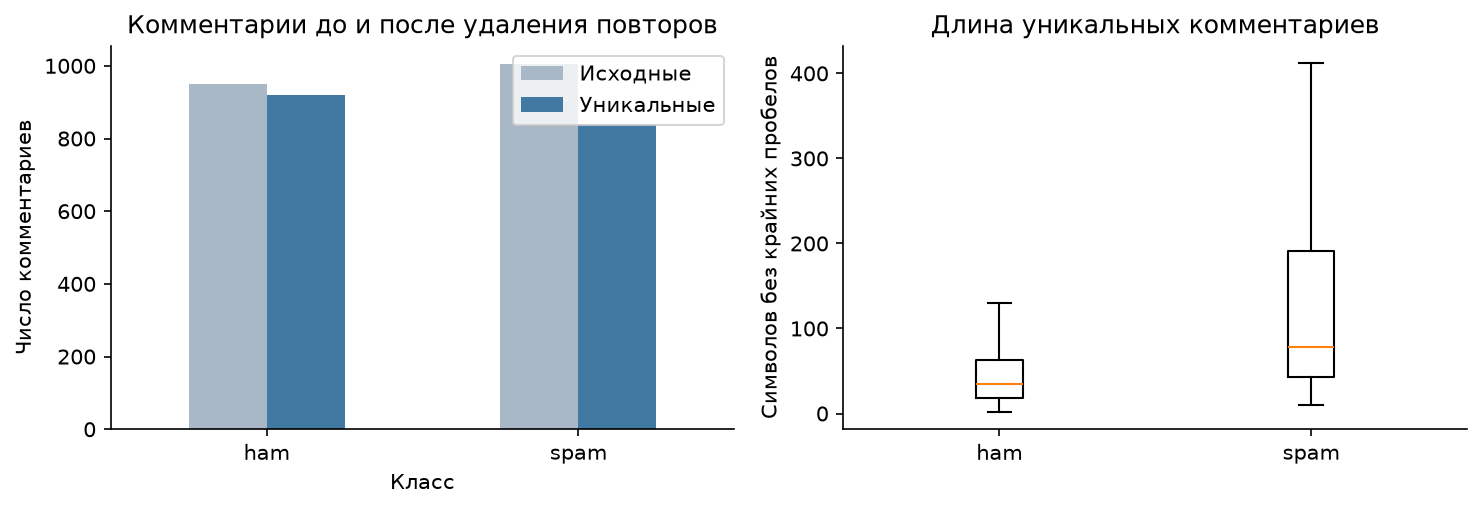

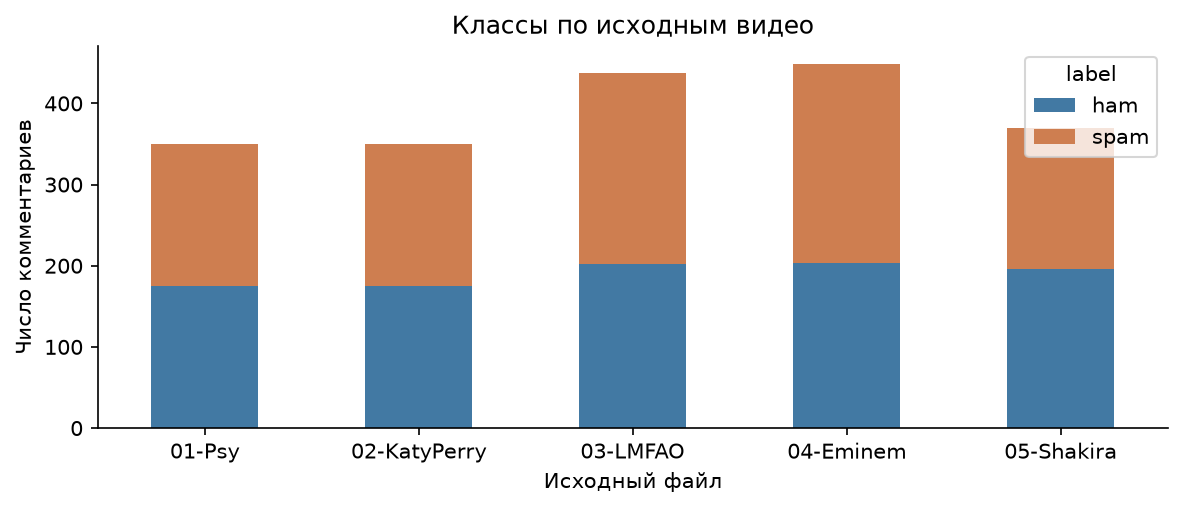

In [4]:
yt = summary['youtube']
display(pd.read_csv(ROOT / 'data/processed/youtube_class_counts.csv'))
display(pd.read_csv(ROOT / 'data/processed/youtube_length_summary.csv'))
display(Image(filename=str(ROOT / 'reports/figures/youtube_balance_and_lengths.png')))
display(Image(filename=str(ROOT / 'reports/figures/youtube_sources.png')))

In [5]:
display(Markdown(f"После удаления {yt['duplicate_text_rows_after_strip']} повторных строк осталось **{yt['unique_clean_rows']}** текстов. Конфликтующих меток у точных повторов: **{yt['conflicting_unique_texts']}**. Длина и наличие ссылок — признаки распределения, а не самостоятельное правило присвоения spam. Нельзя удалять URL без проверки влияния на задачу."))

После удаления 197 повторных строк осталось **1759** текстов. Конфликтующих меток у точных повторов: **0**. Длина и наличие ссылок — признаки распределения, а не самостоятельное правило присвоения spam. Нельзя удалять URL без проверки влияния на задачу.

## RDD2022 United States train

,class,objects,images
0,D00,6750,3907
1,D10,3295,2342
2,D20,834,739
3,D40,135,116


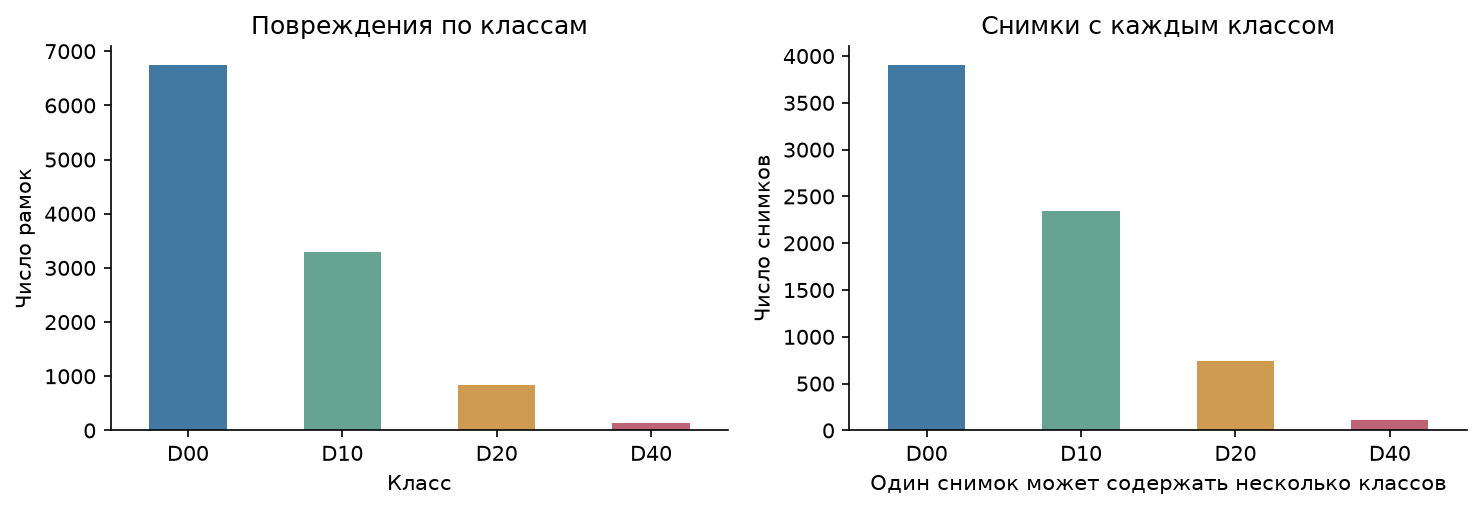

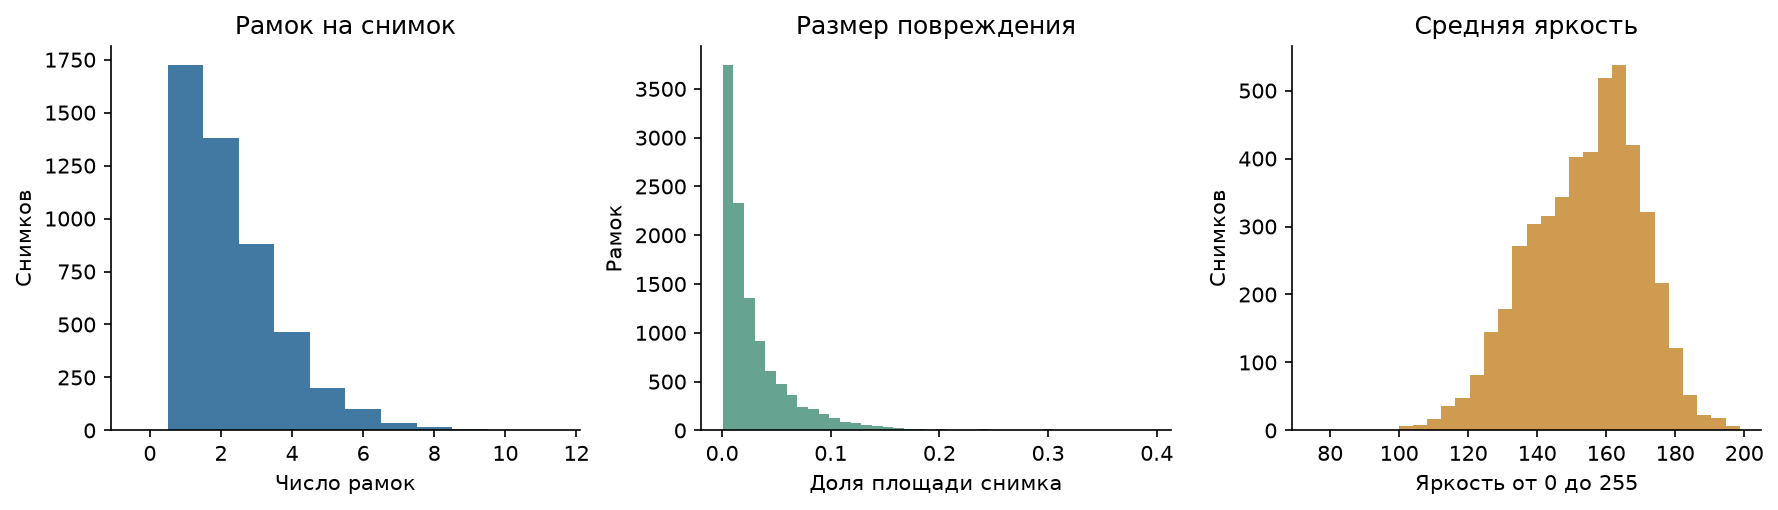

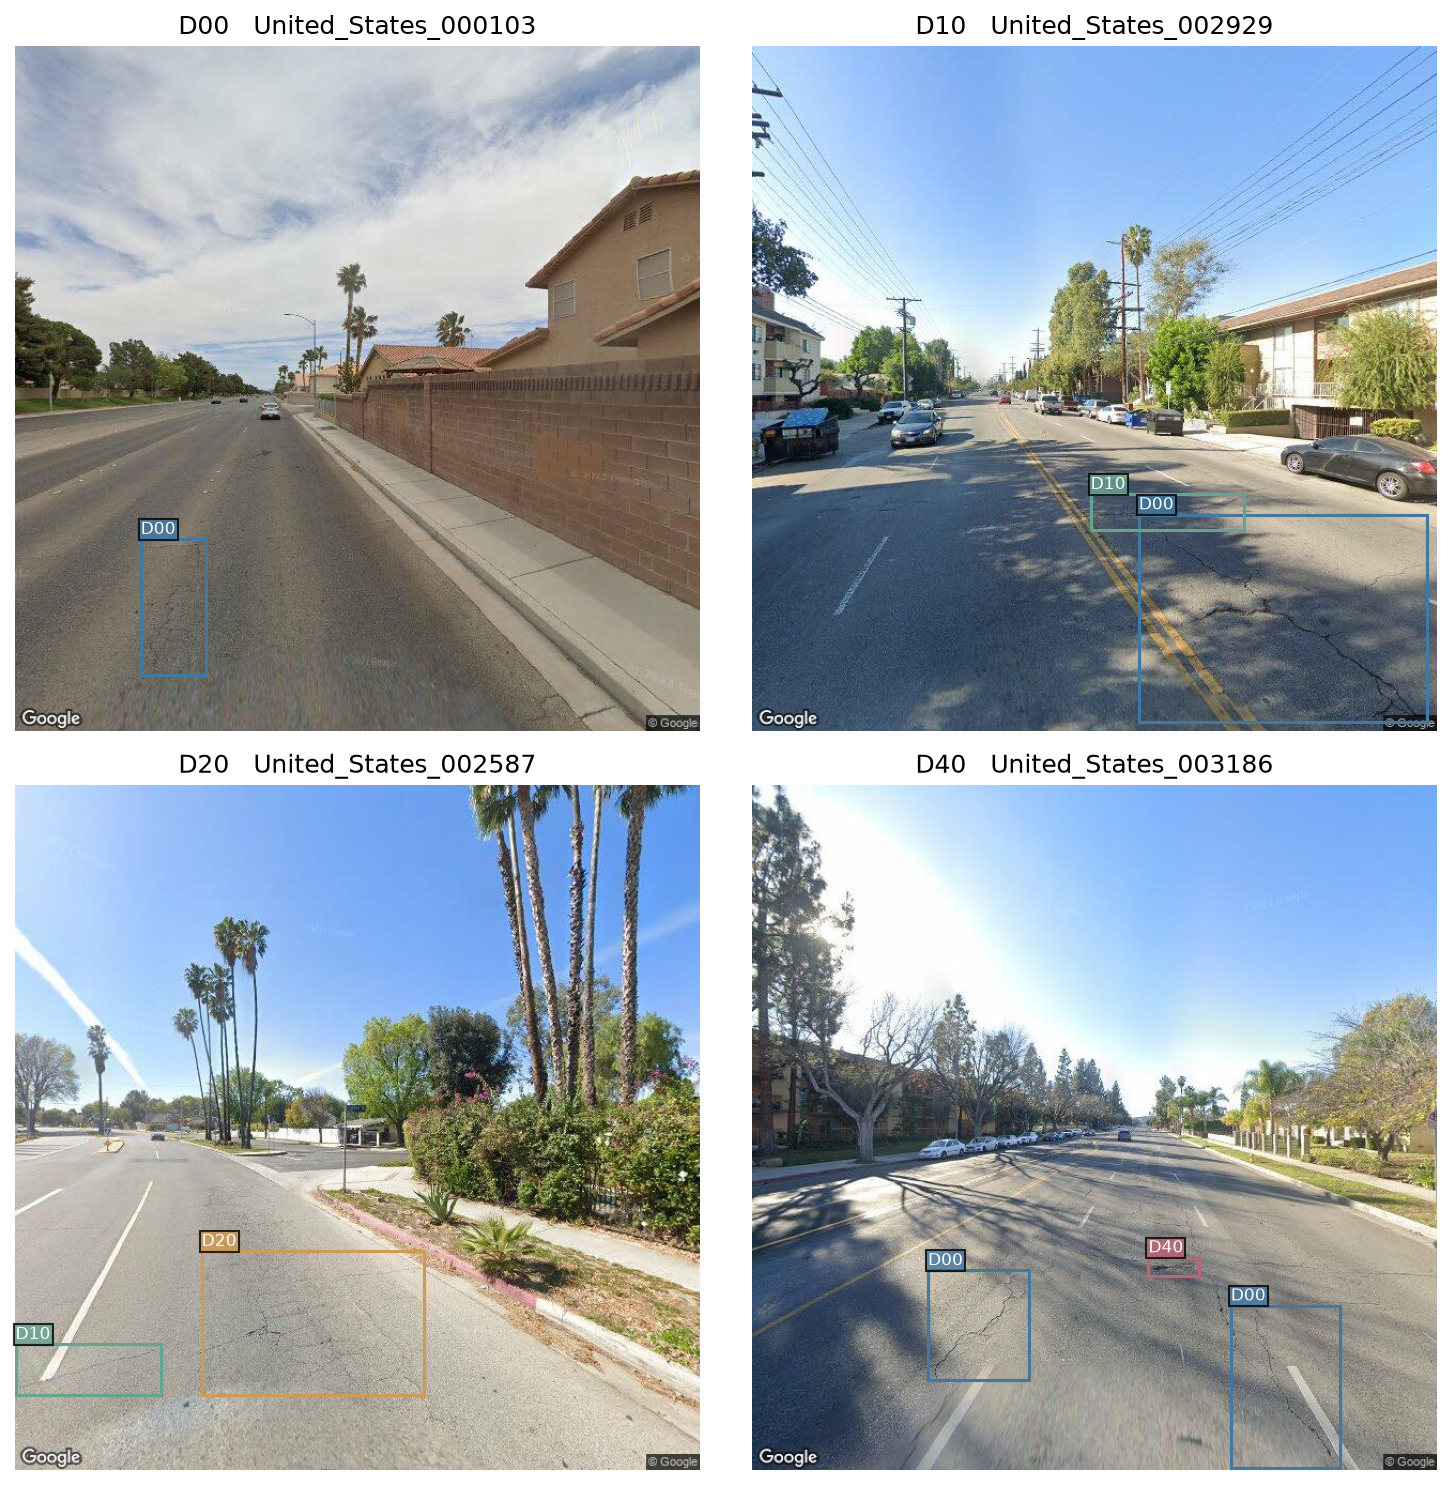

In [6]:
rdd = summary['rdd2022_us']
display(pd.read_csv(ROOT / 'data/processed/rdd_class_counts.csv'))
display(Image(filename=str(ROOT / 'reports/figures/rdd_class_balance.png')))
display(Image(filename=str(ROOT / 'reports/figures/rdd_geometry_and_quality.png')))
display(Image(filename=str(ROOT / 'reports/figures/rdd_annotation_examples.png')))

In [7]:
display(Markdown(f"Проверено **{rdd['readable_paired_train_images']}** изображений и **{rdd['objects']}** рамок. Некорректных рамок: **{rdd['invalid_boxes']}**, ошибок чтения: **{rdd['image_or_pair_errors']}**. Повторных изображений по пикселям: **{rdd['duplicate_pixel_rows']}**; совпадений с официальным test: **{rdd['exact_train_test_overlaps']}**. Кандидатов на близкие повторы: **{rdd['near_duplicate_candidate_pairs_dhash_le3']}** пар, требуется визуальная проверка."))
share = rdd['class_counts_objects']['D40'] / rdd['objects']
display(Markdown(f"На D40 приходится **{share:.2%}** рамок. Следует контролировать метрики каждого класса и представленность выбоин в рабочей выборке. Сумма числа изображений по классам превышает число снимков, потому что задача многоклассовая с несколькими объектами в одном кадре."))

Проверено **4805** изображений и **11014** рамок. Некорректных рамок: **0**, ошибок чтения: **0**. Повторных изображений по пикселям: **1**; совпадений с официальным test: **1**. Кандидатов на близкие повторы: **28** пар, требуется визуальная проверка.

На D40 приходится **1.23%** рамок. Следует контролировать метрики каждого класса и представленность выбоин в рабочей выборке. Сумма числа изображений по классам превышает число снимков, потому что задача многоклассовая с несколькими объектами в одном кадре.

## Предварительные рабочие выборки

Сохранены манифесты с seed 42: 1 500 уникальных текстов, по 750 на класс, и 3 000 изображений из доступных уникальных валидных train-снимков. Для изображений исключены точные повторы и известное совпадение с официальным test. Близкие повторы ещё требуют проверки и группировки. Это не окончательная подготовка к обучению.

In [8]:
text_manifest = pd.read_csv(ROOT / 'data/processed/youtube_working_manifest_1500.csv')
image_manifest = pd.read_csv(ROOT / 'data/processed/rdd_working_manifest_3000.csv')
assert len(text_manifest) == 1500 and text_manifest.text_sha256.nunique() == 1500
assert len(image_manifest) == 3000 and image_manifest.pixel_sha256.nunique() == 3000
print('Уникальных текстов в манифесте:', len(text_manifest))
print('Уникальных изображений в манифесте:', len(image_manifest))
print('Классы рамок в рабочей выборке:', rdd['working_class_counts_objects'])

Уникальных текстов в манифесте: 1500
Уникальных изображений в манифесте: 3000
Классы рамок в рабочей выборке: {'D00': 4230, 'D10': 2072, 'D20': 498, 'D40': 87}


## Выводы и дальнейшая работа

1. Оба выбранных набора позволяют начать исследование; объём рабочих манифестов выше минимума задания.
2. До разбиения нужно исключать повторы. Близкие кадры одного участка дороги следует помещать в одну группу; dHash служит только подсказкой для проверки. Для текста предстоит проверить шаблонные и близкие повторы, не ограничиваясь точным совпадением.
3. Американская часть RDD2022 имеет сильный дисбаланс классов. Выборка одной страны ограничивает обобщение на другие страны и на собственную съёмку.
4. Официальный RDD test не имеет открытых ответов. Собственные train/validation/test и групповые фолды формируются из размеченных данных на следующем этапе.
5. Источники новых данных перечислены в `docs/sources_preliminary.csv`. Нужно собрать по 50–100 новых примеров каждого класса, составить codebook и выполнить независимую разметку двумя участниками.
6. Это анализ **до обогащения**. Сравнение после ручного и синтетического дополнения, согласованность, FID, обучение четырёх вариантов и устойчивость будут рассчитаны после выполнения соответствующих этапов.
